# Introduction

In part 1 of this assessment, you will complete several requested SQL queries in order to extract data, analyze, and provide insights from a single provided SQL database. You will also visualize the key results of 3 of these queries. There are also several 'Reflection' questions that ask you to write out a text based answer in the provided markdown cell. Following the guided question and answer section, in part 2 you will explore a second dataset on your own using SQL in order to conduct a preliminary analysis. You will be asked to produce a very short slide presentation highlighting the work you did for this second section.

## Objectives
You will be able to:
- Interpret "word problems" and translate them into SQL queries
- Decide and perform whichever type of JOIN is best for retrieving desired data
- Use GROUP BY statements to apply aggregate functions like COUNT, MAX, MIN, and SUM
- Use the HAVING clause to compare different aggregates
- Write subqueries to decompose complex queries
- Visualize data using matplotlib, seaborn, or pandas
- Choose the correct chart type based on the given data


## Part 1: Guided SQL Queries

### Your Task: Querying a Customer Database

![toy car picture](images/toycars.jpg)


### Business Understanding
Your employer sells wholesale miniature models of products such as classic cars, motorcycles, and planes. They want you to pull several reports on different segments of their past customers, in order to better understand past sales as well as determine which customers will receive promotional material. They are also interested in investigating which products have performed the best, as well as having several smaller asks.

In addition to providing the requested data from the SQL database you have also been asked to create some basic visuals to display some of the more insightful information. It is up to your discretion to choose the correct plot/chart type for the data in question. **Questions that want you to visualize the results will be explicitly marked**.

### Data Understanding
You may remember this database from a previous lab. As a refresher, here's the ERD diagram for this database:

![ERD picture](images/ERD.png)

The queries you are asked to write will become more complex over the course of the lab.



### Getting Started
For this assessment you are expected to make use of both sqlite3 and the Pandas libraries in order to write, execute, and return SQL queries as a Pandas DataFrame. Assign each returned answer as its own explicit variable.

For the visualization piece you are expected to utilize either Pandas, Seaborn, or Matplotlib to create your visuals. Make sure you are providing verbose labels and titles according to the data you are being asked to visualize. Do not worry too much about choosing a 'style' or 'context' instead focus on conveying the requested information correctly.

### Step 1: Connect to Data

In the cell below
- Import the necessary libraries
- Establish a connection to the database data.sqlite

In [1]:
# Replace None with your code
# Imports
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import sqlite3

# Create connection to database
conn = sqlite3.connect("data.sqlite")

### Step 2: Limited Edition California Product
The California sales rep team is interested in running promotional material for a new limited edition model they are releasing based on the famous San Francisco Cable Cars. This product will only be available to customer stores based in California and given its high price value they want to first target promotional material to existing California customers with a high credit limit. Upon communicating with the accounting department, a credit limit of over 25,000 is considered to be high. 

Execute a SQl query that returns which customers the sales rep team wants to market to first.
*Hint*: Make sure creditLimit is numeric.

In [7]:
# Replace None with your code
limited_edition = pd.read_sql_query(
    """
    SELECT *
    FROM customers
    WHERE state = 'CA' 
        AND CAST(creditLimit AS REAL) > 25000
    ;""", conn)
limited_edition

,customerNumber,customerName,contactLastName,contactFirstName,phone,addressLine1,addressLine2,city,state,postalCode,country,salesRepEmployeeNumber,creditLimit
0,124,Mini Gifts Distributors Ltd.,Nelson,Susan,4155551450,5677 Strong St.,,San Rafael,CA,97562,USA,1165,210500.00
1,129,Mini Wheels Co.,Murphy,Julie,6505555787,5557 North Pendale Street,,San Francisco,CA,94217,USA,1165,64600.00
2,161,Technics Stores Inc.,Hashimoto,Juri,6505556809,9408 Furth Circle,,Burlingame,CA,94217,USA,1165,84600.00
3,205,Toys4GrownUps.com,Young,Julie,6265557265,78934 Hillside Dr.,,Pasadena,CA,90003,USA,1166,90700.00
4,239,Collectable Mini Designs Co.,Thompson,Valarie,7605558146,361 Furth Circle,,San Diego,CA,91217,USA,1166,105000.00
5,321,Corporate Gift Ideas Co.,Brown,Julie,6505551386,7734 Strong St.,,San Francisco,CA,94217,USA,1165,105000.00
6,347,"Men 'R' US Retailers, Ltd.",Chandler,Brian,2155554369,6047 Douglas Av.,,Los Angeles,CA,91003,USA,1166,57700.00
7,450,The Sharp Gifts Warehouse,Frick,Sue,4085553659,3086 Ingle Ln.,,San Jose,CA,94217,USA,1165,77600.00
8,475,West Coast Collectables Co.,Thompson,Steve,3105553722,3675 Furth Circle,,Burbank,CA,94019,USA,1166,55400.00
9,487,Signal Collectibles Ltd.,Taylor,Sue,4155554312,2793 Furth Circle,,Brisbane,CA,94217,USA,1165,60300.00


### Step 3: International Collectable Campaign

The international sales rep team has reached out to you to help them identify partners for a 'Collectable' marketing campaign that highlights the potential collectors value in purchasing these model kits. They want to try and promote a 'collect them all' mentality. The team had a great idea to partner with any of their international customers (non-US) who have "Collect" in their name as a tie in to the larger theme.

Execute a SQL that returns the customers in question.

In [11]:
# Replace None with your code
collectable_campaign = pd.read_sql(
    """
    SELECT *
    FROM customers
    WHERE country != 'USA' 
        AND customerName LIKE '%Collect%'
    ;""", conn
)
collectable_campaign

,customerNumber,customerName,contactLastName,contactFirstName,phone,addressLine1,addressLine2,city,state,postalCode,country,salesRepEmployeeNumber,creditLimit
0,114,"Australian Collectors, Co.",Ferguson,Peter,03 9520 4555,636 St Kilda Road,Level 3,Melbourne,Victoria,3004,Australia,1611,117300.00
1,189,"Clover Collections, Co.",Cassidy,Dean,+353 1862 1555,25 Maiden Lane,Floor No. 4,Dublin,,2,Ireland,1504,69400.00
2,201,"UK Collectables, Ltd.",Devon,Elizabeth,(171) 555-2282,"12, Berkeley Gardens Blvd",,Liverpool,,WX1 6LT,UK,1501,92700.00
3,211,"King Kong Collectables, Co.",Gao,Mike,+852 2251 1555,Bank of China Tower,1 Garden Road,Central Hong Kong,,,Hong Kong,1621,58600.00
4,227,Heintze Collectables,Ibsen,Palle,86 21 3555,Smagsloget 45,,Århus,,8200,Denmark,1401,120800.00
5,260,"Royal Canadian Collectables, Ltd.",Lincoln,Elizabeth,(604) 555-4555,23 Tsawassen Blvd.,,Tsawassen,BC,T2F 8M4,Canada,1323,89600.00
6,293,BG&E Collectables,Harrison,Ed,+41 26 425 50 01,Rte des Arsenaux 41,,Fribourg,,1700,Switzerland,,0.00
7,353,Reims Collectables,Henriot,Paul,26.47.1555,59 rue de l'Abbaye,,Reims,,51100,France,1337,81100.00
8,376,Precious Collectables,Urs,Braun,0452-076555,Hauptstr. 29,,Bern,,3012,Switzerland,1702,0.00
9,382,Salzburg Collectables,Pipps,Georg,6562-9555,Geislweg 14,,Salzburg,,5020,Austria,1401,71700.00


## Reflection Question:

Describe the WHERE clause you used in the above query to a non-technical manager who wants to be ensured that you are properly filtering and only selecting the requested data. How is the operator and conditional expression you are using acting to accomplish this?

## Type your answer in markdown here!

Remember, we have two conditions here. First being about the location of the customer and name of the customer.

- Location of the Customer: The `WHERE` clause filters the customer records to include only international customers whose names contain the word “Collect.” The condition `country != 'USA'` excludes customers based in the United States, ensuring that only customers from other countries are considered. The `!=` operator means “not equal to.”

- Name of the Customer: The second condition, `customerName LIKE '%Collect%'`, searches for customer names containing “Collect” anywhere in the name. The `LIKE` operator allows us to search for a text pattern, while the `%` symbols represent any number of characters before or after the word. By combining these two conditions, the query returns only customers who meet both requirements, ensuring that the results match the international sales team's marketing campaign criteria.

### Step 4: USA Credit and Inventory Policy - Visual Required
The USA based product team is planning to adjust its credit policies and inventory allocation strategy based on the average credit limit of its customers. They would like to target this strategy at a state level with several goals in mind. 
1. Optimize inventory distribution:
    - States with higher average credit limits might be able to place larger orders, justifying priority in inventory allocation.
    - This could help ensure that states with more purchasing power always have products in stock.
2. Tailor credit policies:
    - Adjust credit limits for new customers based on the state average.
    - Identify states where they might be too conservative or too liberal with credit limits.
3. Target marketing and sales efforts:
    - Focus promotional campaigns on states with higher credit limits, potentially leading to larger orders.
    - Develop strategies to increase sales in states with lower average credit limits.

Execute a SQl query that returns the information required to address this ask.

In [19]:
# Replace None with your code
usa_credit_limits = pd.read_sql("""
SELECT 
    state, 
    AVG(CAST(creditLimit AS REAL)) AS average_credit_limit,
    COUNT(*) AS number_of_customers
FROM customers
WHERE country = 'USA' 
    AND state IS NOT NULL
GROUP BY state
ORDER BY average_credit_limit DESC
;""", conn)
usa_credit_limits

,state,average_credit_limit,number_of_customers
0,NH,114200.000000,1
1,NY,89966.666667,6
2,PA,84766.666667,3
3,CA,83854.545455,11
4,NV,71800.000000,1
5,MA,70755.555556,9
6,CT,57350.000000,4
7,NJ,43000.000000,1


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

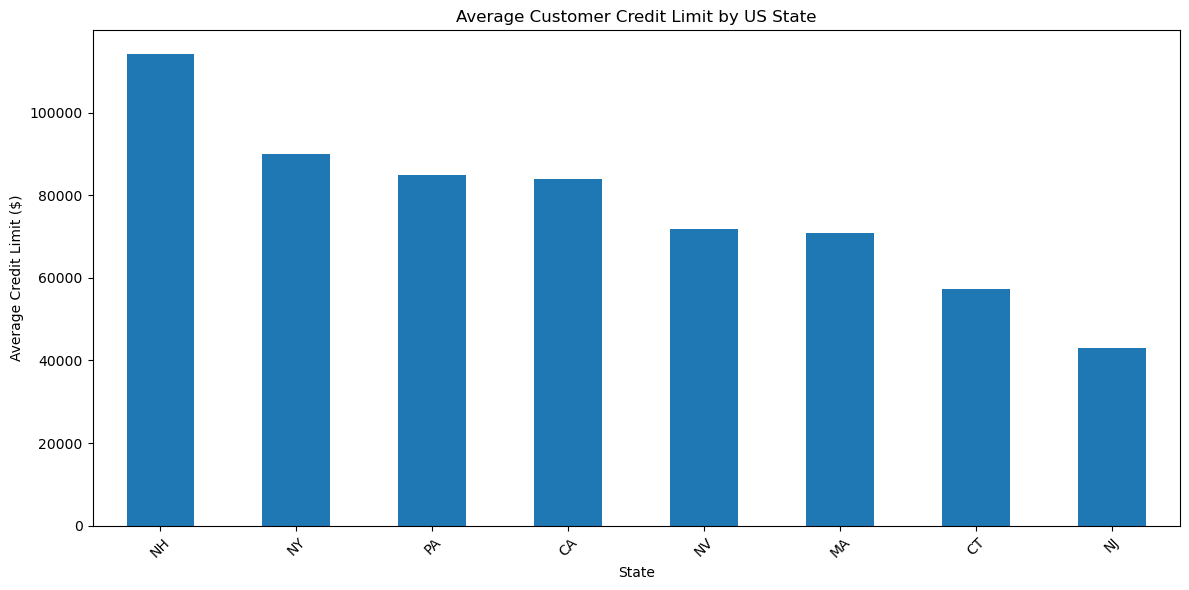

In [20]:
# Replace None with your visual code
# Produce a visual to represent the average credit limit by state
usa_credit_limits.plot(
    kind='bar',
    x='state',
    y='average_credit_limit',
    figsize=(12, 6),
    legend=False
) 

plt.title('Average Customer Credit Limit by US State')
plt.xlabel('State')
plt.ylabel('Average Credit Limit ($)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Step 5: Top Customers - Visual Required
The company is approaching its 10 year anniversary and wants to acknowledge and thank its top customers with personalized communication. They have asked you to determine the top 10 customers based on the total amount of payments made, making sure to return the customer name for clarity. 

Execute a SQl query that returns the information required to address this ask.


In [21]:
# Replace None with your code
top_customers = pd.read_sql(
    """
    SELECT 
        c.customerName, 
        SUM(p.amount) AS total_payments
    FROM customers AS c
    JOIN payments AS p 
        ON c.customerNumber = p.customerNumber
    GROUP BY c.customerNumber, c.customerName
    ORDER BY total_payments DESC
    LIMIT 10
    ;""", conn)
top_customers

,customerName,total_payments
0,Euro+ Shopping Channel,715738.98
1,Mini Gifts Distributors Ltd.,584188.24
2,"Australian Collectors, Co.",180585.07
3,Muscle Machine Inc,177913.95
4,"Dragon Souveniers, Ltd.",156251.03
5,"Down Under Souveniers, Inc",154622.08
6,"AV Stores, Co.",148410.09
7,"Anna's Decorations, Ltd",137034.22
8,Corporate Gift Ideas Co.,132340.78
9,"Saveley & Henriot, Co.",130305.35


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

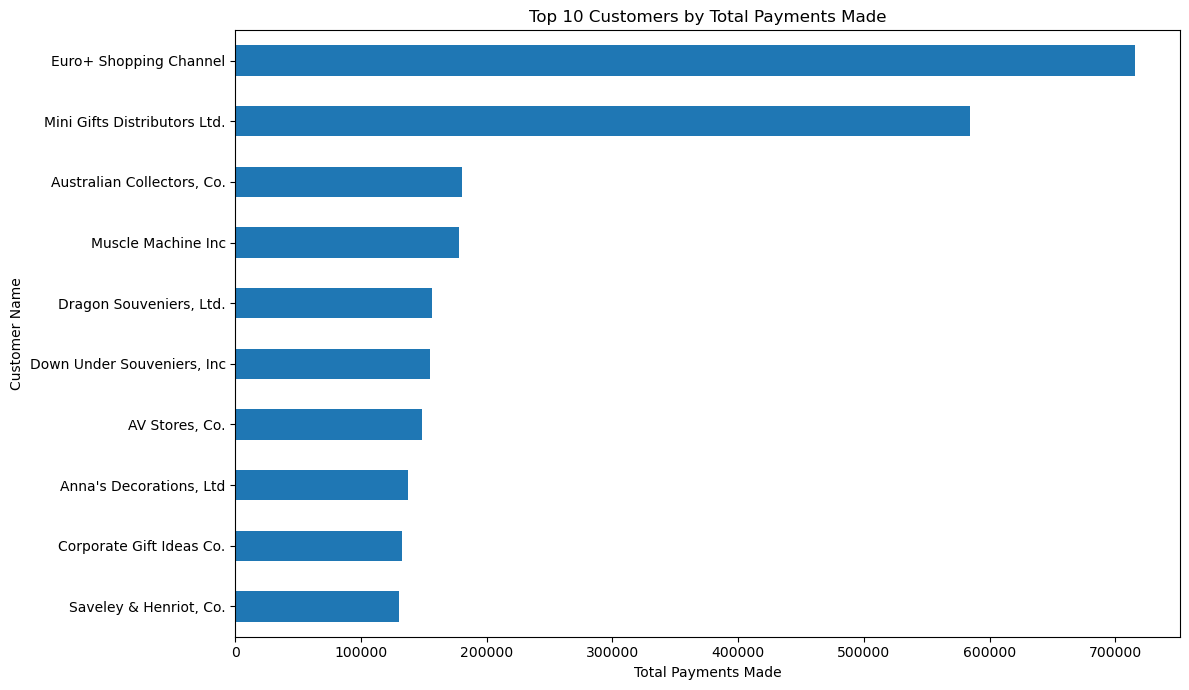

In [26]:
# Replace None with your visual code
# Produce a visual to represent the top ten customers in terms of total payments
top_customers.sort_values(
    by='total_payments'
).plot(
    kind='barh',
    x='customerName',
    y='total_payments',
    figsize=(12, 7),
    legend=False
)

plt.title('Top 10 Customers by Total Payments Made')
plt.xlabel('Total Payments Made')
plt.ylabel('Customer Name')
plt.tight_layout()
plt.show()

### Step 6: Top Customer + Product Quantities
The product team is running an analysis on popular and common products sold to each customer in order to try and determine what new products they should be looking at to include in their catalog. This data will also be used by individual sales reps to recommend similar products to each customer next time they place an order. 

They have asked you to query information, for each customer, about any product they have purchased 10 or more units of. In addition they would like the full set of data to be sorted in ascending order by the total amount purchased.

Execute a SQl query that returns the information required to address this ask.

Hint: For this one, you'll need to make use of HAVING, GROUP BY, and ORDER BY — make sure you get the order of them correct!

In [29]:
# Replace None with you code
customer_product_quantities = pd.read_sql(
    """
    SELECT 
        c.customerName, 
        p.productCode, 
        o.orderNumber, 
        SUM(od.quantityOrdered) AS total_quantity_purchased
    FROM customers AS c
    JOIN orders AS o 
        ON c.customerNumber = o.customerNumber
    JOIN orderdetails AS od 
        ON o.orderNumber = od.orderNumber
    JOIN products AS p 
        ON od.productCode = p.productCode 
    GROUP BY c.customerNumber, c.customerName, 
                p.productCode, p.productName
    HAVING SUM(od.quantityOrdered) >= 10
    ORDER BY total_quantity_purchased ASC
    ;""", conn)
customer_product_quantities

,customerName,productCode,orderNumber,total_quantity_purchased
0,Petit Auto,S18_2949,10423,10
1,"Extreme Desk Decorations, Ltd",S24_4620,10418,10
2,La Rochelle Gifts,S32_2509,10425,11
3,Tekni Collectables Inc.,S700_1691,10401,11
4,The Sharp Gifts Warehouse,S24_3191,10407,13
...,...,...,...,...
2526,Euro+ Shopping Channel,S24_3432,10212,174
2527,Euro+ Shopping Channel,S12_4473,10104,183
2528,Euro+ Shopping Channel,S24_1444,10104,197
2529,Euro+ Shopping Channel,S24_2840,10104,245


### Step 7: Product Analysis - Visual Required

The product team is looking into the demand across its different product lines. They are conducting a comprehensive review of its product portfolio and inventory management strategies. You have been asked to query data pertaining to each different product line, that contains the total quantity ordered and the total number of products for each respective product line. By examining the number of products and total quantity ordered for each product line, the company aims to:
1. Optimize product mix:
    - Identify which product lines have the most diverse offerings (high number of products)
    - Determine which lines are most popular (high total quantity ordered)
    - Compare if lines with more products necessarily lead to more orders
2. Improve inventory management:
    - Adjust stock levels based on the popularity of each product line
    - Identify potential overstocking in lines with low order quantities
    - Ensure adequate variety in high-performing product lines
3. Adjust marketing strategy:
    - Focus promotional efforts on product lines with high potential (many products but lower order quantities)
    - Capitalize on the popularity of high-performing lines in marketing campaigns
4. Advise Product development:
    - Invest in expanding product ranges for lines with high order quantities
    - Consider phasing out or revamping product lines with low numbers of products and low order quantities

Hint: Think about how you can and might have to utilize SQL DISTINCT statement

Execute a SQl query that returns the information required to address this ask.

In [30]:
# Replace None with your code
product_line_analysis = pd.read_sql(
    """
    SELECT 
        p.productLine, 
        COUNT(DISTINCT p.productCode) AS number_of_products, 
        SUM(od.quantityOrdered) AS total_quantity_ordered
    FROM products AS p
    JOIN orderdetails AS od 
        ON p.productCode = od.productCode
    GROUP BY p.productLine
    ORDER BY total_quantity_ordered DESC
    ;""", conn
)
product_line_analysis

,productLine,number_of_products,total_quantity_ordered
0,Classic Cars,37,35582
1,Vintage Cars,24,22933
2,Motorcycles,13,12778
3,Planes,12,11872
4,Trucks and Buses,11,11001
5,Ships,9,8532
6,Trains,3,2818


Once you have the information returned in a dataframe, select an appropriate visualization to represent the relationship between total quantity ordered and the number of products in order to perform a preliminary investigation into the question of if more products lead to more orders. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

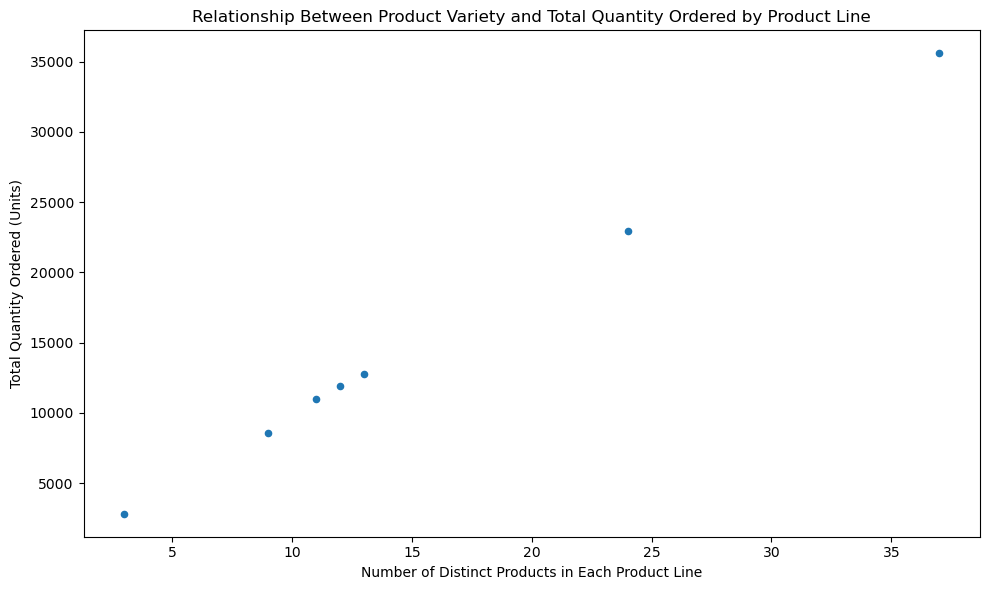

In [31]:
# Replace None with your visual code
# Produce a visual to represent the the relation between number of products and the total amount ordered
product_line_analysis.plot(
    kind='scatter',
    x='number_of_products',
    y='total_quantity_ordered',
    figsize=(10, 6)
)

# Add a descriptive title and axis labels
plt.title('Relationship Between Product Variety and Total Quantity Ordered by Product Line')
plt.xlabel('Number of Distinct Products in Each Product Line')
plt.ylabel('Total Quantity Ordered (Units)')

plt.tight_layout()
plt.show() 

## Reflection Question:

Please explain your choice in the type of visual you used in order to highlight and represent the data from the above query. In a non-technical manner explain why that chart type makes sense for the information being conveyed. What does this visual convey in the context of the question it was asked for?

## Type your answer in markdown here!
I chose a scatter plot because it is useful for showing the relationship between two numerical values: the number of distinct products in each product line and the total quantity ordered. Each point represents one product line, making it easy to compare product variety with customer demand across the company's different product lines.

The visual helps the product team identify patterns in the data. For example, if product lines with more products generally have higher total quantities ordered, this may suggest that a wider product selection is associated with greater demand. If some product lines have many products but low order quantities, the company could investigate whether those products need better marketing or whether its inventory should be adjusted. Similarly, product lines with fewer products but high order quantities may present opportunities to expand their offerings.

Overall, the scatter plot provides a useful starting point for decisions about inventory management, marketing, and product development. However, it does not prove that having more products leads to more orders. Other factors, such as product popularity, pricing, and customer preferences, may also influence demand.

### Step 8: Remote Offices
Upper management is considering a shift to hybrid and remote work for certain locations and roles. They have tasked you with providing them data about employees who work in any office that has fewer than 5 total employees so they can better understand how to support those employees remotely when offices are shut down. 

Be sure to include information about the employees job and supervisor so management can adjust everyone to remote work properly.

Hint: Utilize a subquery to find the relevant offices

Execute a SQl query that returns the information required to address this ask.

In [32]:
# Replace None with your code
remote_office_employees = pd.read_sql_query("""
    SELECT
        e.employeeNumber,
        e.firstName,
        e.lastName,
        e.jobTitle,
        e.officeCode,
        e.reportsTo,
        s.firstName AS supervisor_first_name,
        s.lastName AS supervisor_last_name
    FROM employees AS e
    LEFT JOIN employees AS s
        ON e.reportsTo = s.employeeNumber
    WHERE e.officeCode IN (
        SELECT officeCode
        FROM employees
        GROUP BY officeCode
        HAVING COUNT(*) < 5
    )
    ORDER BY e.officeCode, e.lastName
""", conn)

remote_office_employees

,employeeNumber,firstName,lastName,jobTitle,officeCode,reportsTo,supervisor_first_name,supervisor_last_name
0,1188,Julie,Firrelli,Sales Rep,2,1143,Anthony,Bow
1,1216,Steve,Patterson,Sales Rep,2,1143,Anthony,Bow
2,1286,Foon Yue,Tseng,Sales Rep,3,1143,Anthony,Bow
3,1323,George,Vanauf,Sales Rep,3,1143,Anthony,Bow
4,1625,Yoshimi,Kato,Sales Rep,5,1621,Mami,Nishi
5,1621,Mami,Nishi,Sales Rep,5,1056,Mary,Patterson
6,1611,Andy,Fixter,Sales Rep,6,1088,William,Patterson
7,1619,Tom,King,Sales Rep,6,1088,William,Patterson
8,1612,Peter,Marsh,Sales Rep,6,1088,William,Patterson
9,1088,William,Patterson,Sales Manager (APAC),6,1056,Mary,Patterson


## Reflection Question:

Describe how you decided on the subquery that you used in the query above? This answer can be technically in nature, describing your thought process in how the main query is utilizing the subquery to return the correct data.

## Type your answer in markdown here!

I used a subquery to identify offices that have fewer than five employees before retrieving the employee details. The subquery groups employees by `officeCode` using `GROUP BY officeCode` and then uses `HAVING COUNT(*) < 5` to filter for offices with fewer than five employees. I used `HAVING` rather than `WHERE` because the condition depends on the total number of employees in each group.

The main query uses `WHERE e.officeCode IN (...)` to select employees whose office codes appear in the subquery results. This ensures that only employees working in offices with fewer than five employees are returned. I also used a self-join on the `employees` table to retrieve each employee's supervisor's first and last name, along with their job title and other relevant details. The `LEFT JOIN` ensures that employees are still included even if they do not have a recorded supervisor. This approach allows management to identify employees who may need remote-work support and understand their roles and reporting relationships.

### Step 9: Close the Connection

Now that you are finished executing your queries and retrieving the required information you always want to make sure to close the connection to your database.

In [34]:
# Replace None with your code
conn.close()

### End of Guided Section
In this initial portion of the assessment, you produced several data queries and visualizations for a model company, mainly focused around its customer and product data. You wrote and engineered specific SQL queries to address pertinent questions and asks from the company. Along the way, you utilized many of the major concepts and keywords associated with SQL SELECT queries: FROM, WHERE, GROUP BY, HAVING, ORDER BY, JOIN, SUM, COUNT, and AVG.

## Part 2: Exploratory Analysis with SQL
In this open-ended exploratory section, you will analyze real-world data from the movie industry. As a data analyst, you have the freedom to investigate questions and topics that intrigue you within this dataset. The database schema and Entity-Relationship Diagram (ERD) are provided below for your reference. A general overview and instructions are also provided below.

In [53]:
# Run this cell without changes
import zipfile

zip_file_path = 'im.db.zip'
extract_to_path = './'

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to_path)

# Connection
conn4 = sqlite3.connect('im.db')

# Schema
schema_df = pd.read_sql("""
SElECT * FROM sqlite_master                        
""", conn4)
schema_df

,type,name,tbl_name,rootpage,sql
0,table,movie_basics,movie_basics,2,"CREATE TABLE ""movie_basics"" (\n""movie_id"" TEXT..."
1,table,directors,directors,3,"CREATE TABLE ""directors"" (\n""movie_id"" TEXT,\n..."
2,table,known_for,known_for,4,"CREATE TABLE ""known_for"" (\n""person_id"" TEXT,\..."
3,table,movie_akas,movie_akas,5,"CREATE TABLE ""movie_akas"" (\n""movie_id"" TEXT,\..."
4,table,movie_ratings,movie_ratings,6,"CREATE TABLE ""movie_ratings"" (\n""movie_id"" TEX..."
5,table,persons,persons,7,"CREATE TABLE ""persons"" (\n""person_id"" TEXT,\n ..."
6,table,principals,principals,8,"CREATE TABLE ""principals"" (\n""movie_id"" TEXT,\..."
7,table,writers,writers,9,"CREATE TABLE ""writers"" (\n""movie_id"" TEXT,\n ..."


## The Data

![movie ERD](images/movie_data_erd.jpeg)
### Database Content:

- Source: IMDB
- Time Range: Movies released between 2010 and 2019
- Note: Exclude any movies with a start_year after 2019 as this data is not current or accurate

Available Data Categories:
- Genre
- Runtime
- Personnel (writers, directors, actors)
- Movie ratings

### Objectives:

Initial Exploration:
- Use SQL in combination with Pandas to explore the database
- Identify interesting trends, patterns, or relationships in the data

Business Question Formulation:
- Develop at least one substantial business question for deeper analysis
- Ensure the question is relevant, specific, and can be addressed with the available data

Data Cleaning Assessment:
- Identify potential data cleaning tasks necessary for your deeper analysis
- Note: You are not required to perform the cleaning, only to recognize and list the necessary tasks

Null Value Handling:
- Be aware that the dataset contains null values in certain fields
- Exclude these null values from your exploration
- Do not attempt to input or fill in missing information

### Deliverables:

You need to produce a short slide presentation (3-5 slides) that highlights the three key deliverables below. Utilize a data visualization to support the second deliverable.

1. A summary of your initial data exploration findings
    - Can be bulleted or sentence form
2. At least one well-formulated business question for further analysis
    - Should stem from a relevant trend or pattern your initial exploration identified
3. A list of potential data cleaning tasks identified during your exploration
    - This can and should include things like data normalization/standardization and null handling

Tips for Success:

Begin with broad exploratory queries to understand the data's scope and content. Then focus on honing in on interesting relationships between different data categories. Consider industry trends, audience preferences, or financial aspects when formulating your business question. Pay attention to data quality issues, inconsistencies, or limitations that might affect your analysis. Remember, the goal is to demonstrate your analytical thinking and ability to derive meaningful insights from complex datasets. Good luck with your exploration!

NOTE: You do not need to explore every aspect of this database. Find something that you think is interesting or relevant about the data and focus your exploration there.

### Exploring the Database Schema

The goal is to find meaningful trends in movies released between 2010 and 2019, formulate a business question, create a visualization, and identify potential data-cleaning tasks for your presentation.

Our main research question will be:

**Which movie genres received the highest average audience ratings between 2010 and 2019, and how much confidence should we place in those ratings based on the number of audience votes?**

In [54]:
# Begin your code here
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

# Display the available database tables
tables_df = pd.read_sql_query("""
    SELECT name AS table_name
    FROM sqlite_master
    WHERE type = 'table'
    ORDER BY name
""", conn4)

tables_df

,table_name
0,directors
1,known_for
2,movie_akas
3,movie_basics
4,movie_ratings
5,persons
6,principals
7,writers


In [55]:
# Display the database schema
schema_df = pd.read_sql_query("""
    SELECT name, sql
    FROM sqlite_master
    WHERE type IN ('table', 'view')
    ORDER BY name
""", conn4)

schema_df

,name,sql
0,directors,"CREATE TABLE ""directors"" (\n""movie_id"" TEXT,\n..."
1,known_for,"CREATE TABLE ""known_for"" (\n""person_id"" TEXT,\..."
2,movie_akas,"CREATE TABLE ""movie_akas"" (\n""movie_id"" TEXT,\..."
3,movie_basics,"CREATE TABLE ""movie_basics"" (\n""movie_id"" TEXT..."
4,movie_ratings,"CREATE TABLE ""movie_ratings"" (\n""movie_id"" TEX..."
5,persons,"CREATE TABLE ""persons"" (\n""person_id"" TEXT,\n ..."
6,principals,"CREATE TABLE ""principals"" (\n""movie_id"" TEXT,\..."
7,writers,"CREATE TABLE ""writers"" (\n""movie_id"" TEXT,\n ..."


### Exploring the Data

**1. Yearly Trend**

In [59]:
# Let's understand the size and distribution 
yearly_movies = pd.read_sql_query("""
    SELECT
        start_year,
        COUNT(*) AS number_of_movies
    FROM movie_basics
    WHERE start_year BETWEEN 2010 AND 2019
    GROUP BY start_year
    ORDER BY start_year
;""", conn4)

yearly_movies

,start_year,number_of_movies
0,2010,11849
1,2011,12900
2,2012,13787
3,2013,14709
4,2014,15589
5,2015,16243
6,2016,17272
7,2017,17504
8,2018,16849
9,2019,8379


In [62]:
total_movies = pd.read_sql(
    """
    SELECT COUNT(*) as sum_of_movies
    FROM movie_basics
    WHERE start_year BETWEEN 2010 AND 2019
    ;""", conn4
)
total_movies

,sum_of_movies
0,145081


Visualizing the data with using a line chart

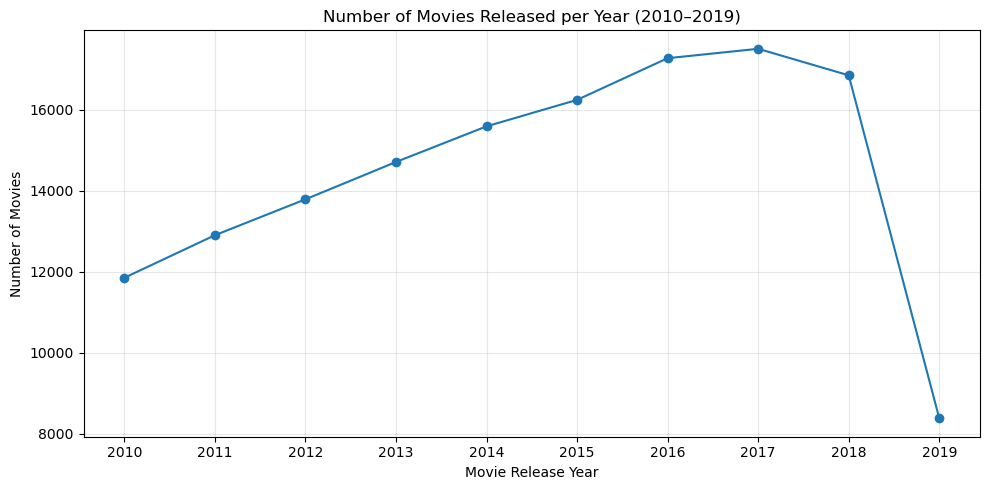

In [41]:
plt.figure(figsize=(10, 5))

plt.plot(
    yearly_movies['start_year'],
    yearly_movies['number_of_movies'],
    marker='o'
)

plt.title('Number of Movies Released per Year (2010–2019)')
plt.xlabel('Movie Release Year')
plt.ylabel('Number of Movies')
plt.xticks(yearly_movies['start_year'])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Observation:** There was a significant drop in number of movies after 2018 with 2019 having the lowest number of movies.

**2. Most Common Genres**

In [43]:
movie_genres = pd.read_sql_query("""
    SELECT
        movie_id,
        primary_title,
        start_year,
        genres
    FROM movie_basics
    WHERE start_year BETWEEN 2010 AND 2019
      AND genres IS NOT NULL
""", conn4)

# Split multiple genres into separate rows
movie_genres['genres'] = movie_genres['genres'].str.split(',')

genre_rows = movie_genres.explode('genres')

# Clean whitespace and remove empty values
genre_rows['genres'] = genre_rows['genres'].str.strip()
genre_rows = genre_rows[
    genre_rows['genres'].notna() &
    (genre_rows['genres'] != '')
]

# Count movies in each genre
genre_counts = (
    genre_rows.groupby('genres')['movie_id']
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name='number_of_movies')
)

genre_counts.head(10)

,genres,number_of_movies
0,Documentary,51556
1,Drama,49545
2,Comedy,25127
3,Thriller,11746
4,Horror,10692
5,Action,10156
6,Romance,9327
7,Biography,8695
8,Crime,6691
9,Adventure,6366


Visualizing the 10 most common genres

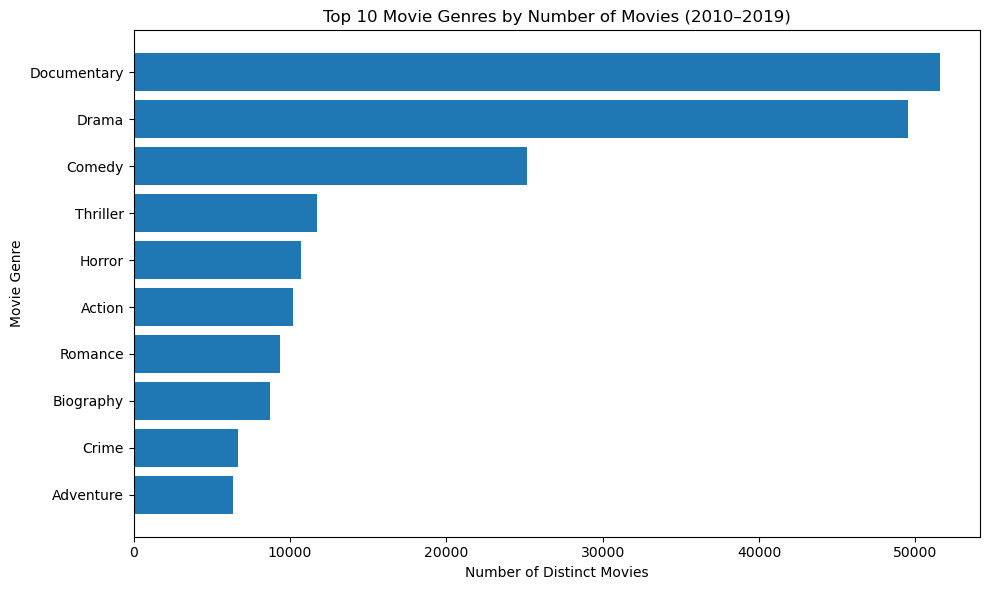

In [44]:
top_genres = genre_counts.head(10).sort_values('number_of_movies')

plt.figure(figsize=(10, 6))

plt.barh(
    top_genres['genres'],
    top_genres['number_of_movies']
)

plt.title('Top 10 Movie Genres by Number of Movies (2010–2019)')
plt.xlabel('Number of Distinct Movies')
plt.ylabel('Movie Genre')
plt.tight_layout()
plt.show()

**Observation:** Documentary and Drama are majorly the two leading genres

**3. Ratings + Genres**

In [45]:
ratings_df = pd.read_sql_query("""
    SELECT
        b.movie_id,
        b.primary_title,
        b.start_year,
        b.genres,
        r.averagerating,
        r.numvotes
    FROM movie_basics AS b
    INNER JOIN movie_ratings AS r
        ON b.movie_id = r.movie_id
    WHERE b.start_year BETWEEN 2010 AND 2019
      AND b.genres IS NOT NULL
      AND r.averagerating IS NOT NULL
      AND r.numvotes IS NOT NULL
""", conn4)

ratings_df.head()

,movie_id,primary_title,start_year,genres,averagerating,numvotes
0,tt0063540,Sunghursh,2013,"Action,Crime,Drama",7.0,77
1,tt0066787,One Day Before the Rainy Season,2019,"Biography,Drama",7.2,43
2,tt0069049,The Other Side of the Wind,2018,Drama,6.9,4517
3,tt0069204,Sabse Bada Sukh,2018,"Comedy,Drama",6.1,13
4,tt0100275,The Wandering Soap Opera,2017,"Comedy,Drama,Fantasy",6.5,119


In [46]:
# split the genre field so that a movie with several genres contributes to each relevant genre
ratings_df['genres'] = ratings_df['genres'].str.split(',')

ratings_by_genre = ratings_df.explode('genres').copy()

ratings_by_genre['genres'] = ratings_by_genre['genres'].str.strip()

ratings_by_genre = ratings_by_genre[
    ratings_by_genre['genres'].notna() &
    (ratings_by_genre['genres'] != '')
]

In [47]:
# calculate the average rating, number of distinct movies, and total audience votes for each genre

genre_ratings = (
    ratings_by_genre.groupby('genres')
    .agg(
        average_rating=('averagerating', 'mean'),
        number_of_movies=('movie_id', 'nunique'),
        total_votes=('numvotes', 'sum')
    )
    .reset_index()
)

# Keep genres with at least 30 movies
genre_ratings = genre_ratings[
    genre_ratings['number_of_movies'] >= 30
]

genre_ratings = genre_ratings.sort_values(
    'average_rating',
    ascending=False
)

genre_ratings

,genres,average_rating,number_of_movies,total_votes
7,Documentary,7.332090,17753,4739345
17,News,7.271330,579,123319
4,Biography,7.162274,3809,21609446
14,Music,7.091972,1968,5453369
12,History,7.040956,2825,7843349
22,Sport,6.961493,1179,3755824
24,War,6.584291,853,2684725
15,Musical,6.498336,721,1387965
8,Drama,6.401559,30788,119567500
9,Family,6.394725,3412,8636710


Visualizing using a horizontal bar chart

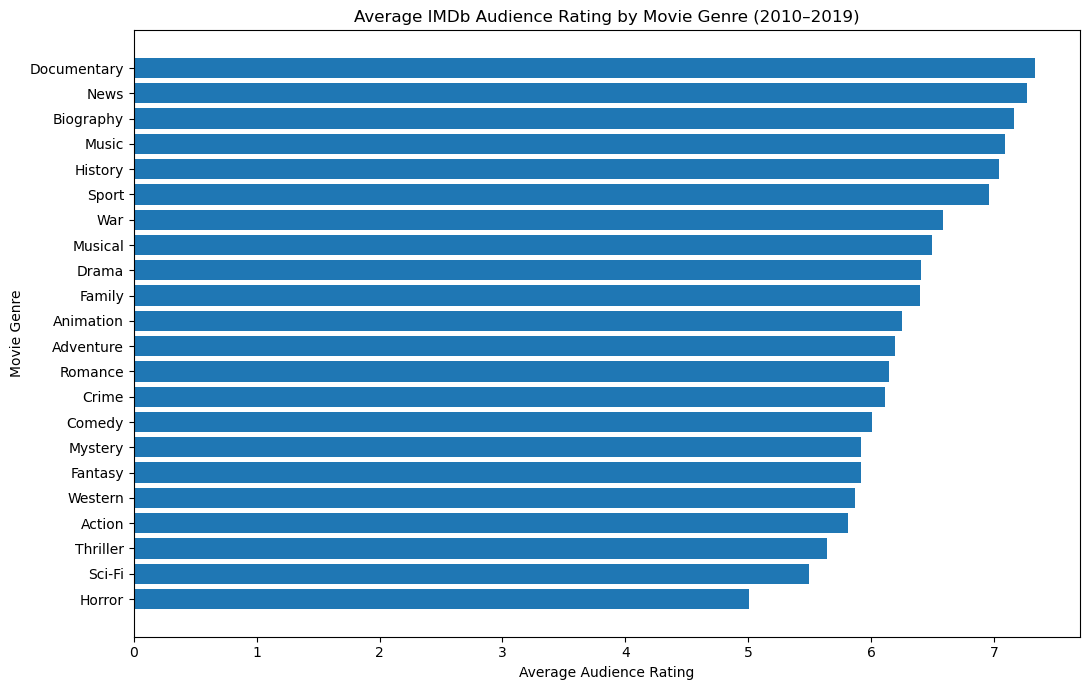

In [48]:
chart_data = genre_ratings.sort_values('average_rating')

plt.figure(figsize=(11, 7))

plt.barh(
    chart_data['genres'],
    chart_data['average_rating']
)

plt.title(
    'Average IMDb Audience Rating by Movie Genre (2010–2019)'
)
plt.xlabel('Average Audience Rating')
plt.ylabel('Movie Genre')
plt.tight_layout()
plt.show()

**Observation:** The genre Documentary has the highest average and Horror with the least.

**4. Examining number of audience votes**

A high average rating based on a small audience may be less representative than a similar rating supported by many votes. We'll create a scatter plot to confirm this.

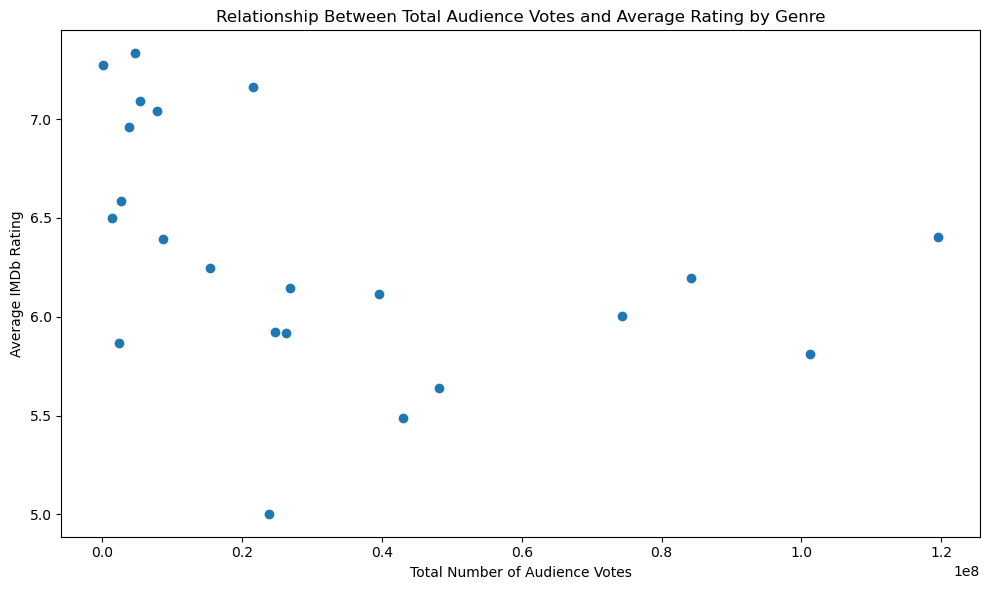

In [49]:
plt.figure(figsize=(10, 6))

plt.scatter(
    genre_ratings['total_votes'],
    genre_ratings['average_rating']
)

plt.title(
    'Relationship Between Total Audience Votes and Average Rating by Genre'
)
plt.xlabel('Total Number of Audience Votes')
plt.ylabel('Average IMDb Rating')
plt.tight_layout()
plt.show()

**Observation:**
- Genres with more votes have a larger audience voting on their titles.
- The vertical position shows the average rating.
- A high vote count does not automatically mean a high rating.

Close the connection.

In [50]:
conn4.close()